
# WORKSHOP 003
## ETL Pipeline using Apache Kafka + Machine Learning

**Course:** ETL (G01)

### Objective
Develop an ETL pipeline using Apache Kafka to consume happiness records, perform Exploratory Data Analysis (EDA), prepare features, train a regression model and evaluate its predictive performance.

### Technologies
- Python 3.11
- Apache Kafka
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook


In [1]:
import sys
import pandas as pd
import numpy as np
import confluent_kafka
import sklearn

print("PYTHON:", sys.version)
print("ENTORNO:", sys.executable)
print("PANDAS:", pd.__version__)
print("KAFKA:", confluent_kafka.__version__)
print("TODO FUNCIONA CORRECTAMENTE")

PYTHON: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
ENTORNO: c:\Users\velas\Documents\Workshop003\.venv\Scripts\python.exe
PANDAS: 3.1.1
KAFKA: 2.16.2
TODO FUNCIONA CORRECTAMENTE


In [2]:
# 2. CONFIGURACIÓN DE KAFKA

import certifi
import getpass
from confluent_kafka import Consumer

KAFKA_CONFIG = {
    "bootstrap.servers": "kafka-classroom-2026.westus.cloudapp.azure.com:9092",
    "security.protocol": "SASL_SSL",
    "sasl.mechanism": "SCRAM-SHA-512",
    "sasl.username": "classroom-students",
    "sasl.password": getpass.getpass("Contraseña Kafka: "),
    "ssl.ca.location": certifi.where(),
    "group.id": "workshop003-velas",
    "auto.offset.reset": "earliest",
    "enable.auto.commit": False
}

consumer = Consumer(KAFKA_CONFIG)

consumer.subscribe(["etl.records"])

print("Consumidor Kafka configurado correctamente")
print("Topic: etl.records")

Consumidor Kafka configurado correctamente
Topic: etl.records


In [3]:
# 3. EXTRACCIÓN DE DATOS DESDE KAFKA

import time

mensajes_raw = []
tiempo_inicio = time.time()
tiempo_maximo = 20

print("Conectando y esperando mensajes de Kafka...")

while time.time() - tiempo_inicio < tiempo_maximo and len(mensajes_raw) < 100:
    msg = consumer.poll(1.0)

    if msg is None:
        continue

    if msg.error():
        print("Error Kafka:", msg.error())
        continue

    valor = msg.value().decode("utf-8")
    mensajes_raw.append(valor)

print("\nExtracción finalizada.")
print("Total de mensajes recibidos:", len(mensajes_raw))

if mensajes_raw:
    print("\nPrimeros 3 mensajes:")
    for i, mensaje in enumerate(mensajes_raw[:3], start=1):
        print(f"\nMensaje {i}:")
        print(mensaje[:1000])
else:
    print("No se recibieron mensajes durante los 20 segundos.")

Conectando y esperando mensajes de Kafka...

Extracción finalizada.
Total de mensajes recibidos: 100

Primeros 3 mensajes:

Mensaje 1:
{"metadata": {"source_file": "2015.csv", "year": 2015, "record_id": "2015-1"}, "data": {"Country": "Switzerland", "Region": "Western Europe", "Happiness Rank": 1, "Happiness Score": 7.587, "Standard Error": 0.03411, "Economy (GDP per Capita)": 1.39651, "Family": 1.34951, "Health (Life Expectancy)": 0.94143, "Freedom": 0.66557, "Trust (Government Corruption)": 0.41978, "Generosity": 0.29678, "Dystopia Residual": 2.51738}}

Mensaje 2:
{"metadata": {"source_file": "2015.csv", "year": 2015, "record_id": "2015-2"}, "data": {"Country": "Iceland", "Region": "Western Europe", "Happiness Rank": 2, "Happiness Score": 7.561, "Standard Error": 0.04884, "Economy (GDP per Capita)": 1.30232, "Family": 1.40223, "Health (Life Expectancy)": 0.94784, "Freedom": 0.62877, "Trust (Government Corruption)": 0.14145, "Generosity": 0.4363, "Dystopia Residual": 2.70201}}

Mensaje

In [4]:
# 4. TRANSFORMACIÓN DE MENSAJES JSON A DATAFRAME

import json
import pandas as pd

registros = []
errores_json = []

for mensaje in mensajes_raw:
    try:
        registro = json.loads(mensaje)

        fila = {
            **registro.get("metadata", {}),
            **registro.get("data", {})
        }

        registros.append(fila)

    except (json.JSONDecodeError, TypeError) as e:
        errores_json.append(str(e))

# Crear DataFrame
df = pd.DataFrame(registros)

print("TRANSFORMACIÓN COMPLETADA")
print("-" * 45)
print("Registros procesados:", len(df))
print("Errores de lectura:", len(errores_json))
print("Dimensiones del DataFrame:", df.shape)

display(df.head(10))

TRANSFORMACIÓN COMPLETADA
---------------------------------------------
Registros procesados: 100
Errores de lectura: 0
Dimensiones del DataFrame: (100, 17)


,source_file,year,record_id,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual,Lower Confidence Interval,Upper Confidence Interval
0,2015.csv,2015,2015-1,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738,NaN,NaN
1,2015.csv,2015,2015-2,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201,NaN,NaN
2,2015.csv,2015,2015-7,Netherlands,Western Europe,7,7.378,0.02799,1.32944,1.28017,0.89284,0.61576,0.31814,0.47610,2.46570,NaN,NaN
3,2015.csv,2015,2015-10,Australia,Australia and New Zealand,10,7.284,0.04083,1.33358,1.30923,0.93156,0.65124,0.35637,0.43562,2.26646,NaN,NaN
4,2015.csv,2015,2015-13,Austria,Western Europe,13,7.200,0.03751,1.33723,1.29704,0.89042,0.62433,0.18676,0.33088,2.53320,NaN,NaN
5,2015.csv,2015,2015-14,Mexico,Latin America and Caribbean,14,7.187,0.04176,1.02054,0.91451,0.81444,0.48181,0.21312,0.14074,3.60214,NaN,NaN
6,2015.csv,2015,2015-17,Luxembourg,Western Europe,17,6.946,0.03499,1.56391,1.21963,0.91894,0.61583,0.37798,0.28034,1.96961,NaN,NaN
7,2015.csv,2015,2015-20,United Arab Emirates,Middle East and Northern Africa,20,6.901,0.03729,1.42727,1.12575,0.80925,0.64157,0.38583,0.26428,2.24743,NaN,NaN
8,2015.csv,2015,2015-25,Panama,Latin America and Caribbean,25,6.786,0.04910,1.06353,1.19850,0.79661,0.54210,0.09270,0.24434,2.84848,NaN,NaN
9,2015.csv,2015,2015-27,Chile,Latin America and Caribbean,27,6.670,0.05800,1.10715,1.12447,0.85857,0.44132,0.12869,0.33363,2.67585,NaN,NaN


In [5]:
# 5. EXPLORACIÓN INICIAL DEL DATASET

print("COLUMNAS:")
print(df.columns.tolist())

print("\nTIPOS DE DATOS:")
print(df.dtypes)

print("\nARCHIVOS DE ORIGEN:")
print(df["source_file"].value_counts())

print("\nAÑOS DISPONIBLES:")
print(df["year"].value_counts().sort_index())

print("\nVALORES FALTANTES:")
display(df.isnull().sum())

COLUMNAS:
['source_file', 'year', 'record_id', 'Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual', 'Lower Confidence Interval', 'Upper Confidence Interval']

TIPOS DE DATOS:
source_file                          str
year                               int64
record_id                            str
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Standard Error                   float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
Lower Confidence Interval        float64
U

source_file                       0
year                              0
record_id                         0
Country                           0
Region                            0
Happiness Rank                    0
Happiness Score                   0
Standard Error                   39
Economy (GDP per Capita)          0
Family                            0
Health (Life Expectancy)          0
Freedom                           0
Trust (Government Corruption)     0
Generosity                        0
Dystopia Residual                 0
Lower Confidence Interval        61
Upper Confidence Interval        61
dtype: int64

In [6]:
# 6. ANÁLISIS DE VALORES FALTANTES POR AÑO

print("REGISTROS POR AÑO:")
display(df.groupby(["year", "source_file"]).size().to_frame("Total"))

print("\nVALORES FALTANTES POR AÑO:")

faltantes_anio = df.groupby("year").agg(
    registros=("record_id", "count"),
    standard_error=("Standard Error", lambda x: x.isna().sum()),
    lower_interval=("Lower Confidence Interval", lambda x: x.isna().sum()),
    upper_interval=("Upper Confidence Interval", lambda x: x.isna().sum())
)

display(faltantes_anio)

print("\nPORCENTAJE GENERAL DE VALORES FALTANTES:")
display(
    (df.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

REGISTROS POR AÑO:


,,Total
year,source_file,
2015,2015.csv,61
2016,2016.csv,39



VALORES FALTANTES POR AÑO:


,registros,standard_error,lower_interval,upper_interval
year,,,,
2015,61,0,61,61
2016,39,39,0,0



PORCENTAJE GENERAL DE VALORES FALTANTES:


Upper Confidence Interval        61.0
Lower Confidence Interval        61.0
Standard Error                   39.0
source_file                       0.0
year                              0.0
Region                            0.0
Happiness Rank                    0.0
Country                           0.0
record_id                         0.0
Economy (GDP per Capita)          0.0
Happiness Score                   0.0
Family                            0.0
Health (Life Expectancy)          0.0
Trust (Government Corruption)     0.0
Freedom                           0.0
Dystopia Residual                 0.0
Generosity                        0.0
dtype: float64

In [7]:
# 8. EXTRACCIÓN COMPLETA DESDE KAFKA

import time
import json
from confluent_kafka import Consumer

# Crear un consumidor independiente para recuperar desde el inicio
config_completa = KAFKA_CONFIG.copy()
config_completa["group.id"] = "workshop003-velas-full-20261118"
config_completa["auto.offset.reset"] = "earliest"
config_completa["enable.auto.commit"] = False

consumer_full = Consumer(config_completa)
consumer_full.subscribe(["etl.records"])

mensajes_full = []
errores_kafka = []

inicio = time.monotonic()
ultimo_mensaje = inicio

TIEMPO_MAXIMO = 180
TIEMPO_SIN_MENSAJES = 10

print("Iniciando extracción completa...")
print("Esperando mensajes del tópico etl.records")

try:
    while True:
        ahora = time.monotonic()

        if ahora - inicio >= TIEMPO_MAXIMO:
            print("Se alcanzó el tiempo máximo de extracción.")
            break

        if ahora - ultimo_mensaje >= TIEMPO_SIN_MENSAJES:
            break

        msg = consumer_full.poll(1.0)

        if msg is None:
            continue

        if msg.error():
            errores_kafka.append(str(msg.error()))
            continue

        mensajes_full.append(msg.value().decode("utf-8"))
        ultimo_mensaje = time.monotonic()

        if len(mensajes_full) % 100 == 0:
            print("Mensajes recibidos:", len(mensajes_full))

finally:
    consumer_full.close()

print("\nEXTRACCIÓN FINALIZADA")
print("Total de mensajes:", len(mensajes_full))
print("Errores Kafka:", len(errores_kafka))
print("Tiempo empleado:", round(time.monotonic() - inicio, 2), "segundos")

Iniciando extracción completa...
Esperando mensajes del tópico etl.records
Mensajes recibidos: 100
Mensajes recibidos: 200
Mensajes recibidos: 300
Mensajes recibidos: 400
Mensajes recibidos: 500
Mensajes recibidos: 600
Mensajes recibidos: 700

EXTRACCIÓN FINALIZADA
Total de mensajes: 782
Errores Kafka: 0
Tiempo empleado: 15.42 segundos


In [8]:
# 9. TRANSFORMACIÓN Y VERIFICACIÓN

registros_full = []
errores_json = []

for mensaje in mensajes_full:
    try:
        registro = json.loads(mensaje)

        fila = {
            **registro.get("metadata", {}),
            **registro.get("data", {})
        }

        registros_full.append(fila)

    except (json.JSONDecodeError, TypeError) as e:
        errores_json.append(str(e))

df = pd.DataFrame(registros_full)

print("TOTAL DE REGISTROS:", len(df))
print("ERRORES JSON:", len(errores_json))
print("\nARCHIVOS ENCONTRADOS:")
display(df["source_file"].value_counts())

print("\nREGISTROS POR AÑO:")
display(df.groupby("year").size().sort_index())

print("\nDUPLICADOS:")
print(df["record_id"].duplicated().sum())

print("\nDIMENSIONES:", df.shape)

TOTAL DE REGISTROS: 782
ERRORES JSON: 0

ARCHIVOS ENCONTRADOS:


source_file
2015.csv    158
2016.csv    157
2018.csv    156
2019.csv    156
2017.csv    155
Name: count, dtype: int64


REGISTROS POR AÑO:


year
2015    158
2016    157
2017    155
2018    156
2019    156
dtype: int64


DUPLICADOS:
0

DIMENSIONES: (782, 33)


In [9]:
# 9. TRANSFORMACIÓN Y VERIFICACIÓN

registros_full = []
errores_json = []

for mensaje in mensajes_full:
    try:
        registro = json.loads(mensaje)

        fila = {
            **registro.get("metadata", {}),
            **registro.get("data", {})
        }

        registros_full.append(fila)

    except (json.JSONDecodeError, TypeError) as e:
        errores_json.append(str(e))

df = pd.DataFrame(registros_full)

print("TOTAL DE REGISTROS:", len(df))
print("ERRORES JSON:", len(errores_json))

print("\nARCHIVOS ENCONTRADOS:")
display(df["source_file"].value_counts())

print("\nREGISTROS POR AÑO:")
display(df.groupby("year").size().sort_index())

print("\nDUPLICADOS:")
print(df["record_id"].duplicated().sum())

print("\nDIMENSIONES:", df.shape)

TOTAL DE REGISTROS: 782
ERRORES JSON: 0

ARCHIVOS ENCONTRADOS:


source_file
2015.csv    158
2016.csv    157
2018.csv    156
2019.csv    156
2017.csv    155
Name: count, dtype: int64


REGISTROS POR AÑO:


year
2015    158
2016    157
2017    155
2018    156
2019    156
dtype: int64


DUPLICADOS:
0

DIMENSIONES: (782, 33)


In [10]:
# 10. COMPARACIÓN DE ESTRUCTURAS POR AÑO

columnas_por_archivo = {}

for archivo in sorted(df["source_file"].unique()):
    columnas = set(df[df["source_file"] == archivo].columns)
    columnas_por_archivo[archivo] = columnas

columnas_comunes = set.intersection(*columnas_por_archivo.values())

print("COLUMNAS COMUNES:")
print(sorted(columnas_comunes))

print("\nCOLUMNAS POR ARCHIVO:")

for archivo, columnas in columnas_por_archivo.items():
    print(f"\n{archivo}: {len(columnas)} columnas")
    print(sorted(columnas))

print("\nCOLUMNAS NO COMUNES:")

for archivo, columnas in columnas_por_archivo.items():
    exclusivas = columnas - columnas_comunes
    print(f"{archivo}: {sorted(exclusivas)}")

COLUMNAS COMUNES:
['Country', 'Country or region', 'Dystopia Residual', 'Dystopia.Residual', 'Economy (GDP per Capita)', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Freedom to make life choices', 'GDP per capita', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Happiness.Rank', 'Happiness.Score', 'Health (Life Expectancy)', 'Health..Life.Expectancy.', 'Healthy life expectancy', 'Lower Confidence Interval', 'Overall rank', 'Perceptions of corruption', 'Region', 'Score', 'Social support', 'Standard Error', 'Trust (Government Corruption)', 'Trust..Government.Corruption.', 'Upper Confidence Interval', 'Whisker.high', 'Whisker.low', 'record_id', 'source_file', 'year']

COLUMNAS POR ARCHIVO:

2015.csv: 33 columnas
['Country', 'Country or region', 'Dystopia Residual', 'Dystopia.Residual', 'Economy (GDP per Capita)', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Freedom to make life choices', 'GDP per capita', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Happiness.Rank', '

In [11]:
# 11. CALIDAD DEL DATASET COMPLETO

faltantes = pd.DataFrame({
    "Valores faltantes": df.isnull().sum(),
    "Porcentaje": (df.isnull().mean() * 100).round(2)
})

faltantes = faltantes.sort_values(
    "Porcentaje", ascending=False
)

display(faltantes[faltantes["Valores faltantes"] > 0])

print("Dimensiones:", df.shape)
print("Duplicados completos:", df.duplicated().sum())

,Valores faltantes,Porcentaje
Dystopia.Residual,627,80.18
Whisker.low,627,80.18
Trust..Government.Corruption.,627,80.18
Health..Life.Expectancy.,627,80.18
Economy..GDP.per.Capita.,627,80.18
Happiness.Score,627,80.18
Whisker.high,627,80.18
Happiness.Rank,627,80.18
Upper Confidence Interval,625,79.92
Lower Confidence Interval,625,79.92


Dimensiones: (782, 33)
Duplicados completos: 0


In [12]:
# 10. COMPARACIÓN REAL DE ESTRUCTURAS POR ARCHIVO

import json

columnas_por_archivo = {}

for mensaje in mensajes_full:
    registro = json.loads(mensaje)

    archivo = registro["metadata"]["source_file"]
    columnas = set(registro["data"].keys())

    if archivo not in columnas_por_archivo:
        columnas_por_archivo[archivo] = set()

    columnas_por_archivo[archivo].update(columnas)

# Columnas comunes a los cinco archivos
columnas_comunes = set.intersection(
    *columnas_por_archivo.values()
)

print("COLUMNAS COMUNES A LOS CINCO ARCHIVOS:")
print(sorted(columnas_comunes))

print("\nCOMPARACIÓN POR ARCHIVO:")

for archivo, columnas in sorted(columnas_por_archivo.items()):
    exclusivas = columnas - columnas_comunes

    print(f"\n{archivo}")
    print("Total de columnas:", len(columnas))
    print("Columnas exclusivas:", sorted(exclusivas))

COLUMNAS COMUNES A LOS CINCO ARCHIVOS:
['Generosity']

COMPARACIÓN POR ARCHIVO:

2015.csv
Total de columnas: 12
Columnas exclusivas: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Region', 'Standard Error', 'Trust (Government Corruption)']

2016.csv
Total de columnas: 13
Columnas exclusivas: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval']

2017.csv
Total de columnas: 12
Columnas exclusivas: ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']

2018.csv
Total de columnas: 9
Columnas exclusivas: ['Country or region', 'Freedom to make lif

In [13]:
# 12. NORMALIZACIÓN E INTEGRACIÓN DE LOS CINCO ARCHIVOS

# Recuperar los registros originales de Kafka
registros = []

for mensaje in mensajes_full:
    registro = json.loads(mensaje)

    fila = {
        **registro["metadata"],
        **registro["data"]
    }

    registros.append(fila)

df_original = pd.DataFrame(registros)

# Diccionario de equivalencias entre nombres de columnas
equivalencias = {
    "country": [
        "Country",
        "Country or region"
    ],
    "happiness_score": [
        "Happiness Score",
        "Happiness.Score",
        "Score"
    ],
    "happiness_rank": [
        "Happiness Rank",
        "Happiness.Rank",
        "Overall rank"
    ],
    "gdp_per_capita": [
        "Economy (GDP per Capita)",
        "Economy..GDP.per.Capita.",
        "GDP per capita"
    ],
    "social_support": [
        "Family",
        "Social support"
    ],
    "life_expectancy": [
        "Health (Life Expectancy)",
        "Health..Life.Expectancy.",
        "Healthy life expectancy"
    ],
    "freedom": [
        "Freedom",
        "Freedom to make life choices"
    ],
    "corruption": [
        "Trust (Government Corruption)",
        "Trust..Government.Corruption.",
        "Perceptions of corruption"
    ],
    "dystopia_residual": [
        "Dystopia Residual",
        "Dystopia.Residual"
    ],
    "region": [
        "Region"
    ],
    "standard_error": [
        "Standard Error"
    ],
    "lower_interval": [
        "Lower Confidence Interval",
        "Whisker.low"
    ],
    "upper_interval": [
        "Upper Confidence Interval",
        "Whisker.high"
    ],
    "generosity": [
        "Generosity"
    ]
}

# Crear el DataFrame integrado
df_integrado = pd.DataFrame()

# Conservar los metadatos
for columna in ["source_file", "year", "record_id"]:
    df_integrado[columna] = df_original[columna]

# Consolidar las variables equivalentes
for nombre_nuevo, nombres_originales in equivalencias.items():

    columnas_existentes = [
        columna
        for columna in nombres_originales
        if columna in df_original.columns
    ]

    if columnas_existentes:
        df_integrado[nombre_nuevo] = (
            df_original[columnas_existentes]
            .bfill(axis=1)
            .iloc[:, 0]
        )

print("INTEGRACIÓN FINALIZADA")
print("Dimensiones:", df_integrado.shape)

display(df_integrado.head())

print("\nVALORES FALTANTES:")
display(
    df_integrado.isnull().sum()
    .sort_values(ascending=False)
)

INTEGRACIÓN FINALIZADA
Dimensiones: (782, 17)


,source_file,year,record_id,country,happiness_score,happiness_rank,gdp_per_capita,social_support,life_expectancy,freedom,corruption,dystopia_residual,region,standard_error,lower_interval,upper_interval,generosity
0,2015.csv,2015,2015-4,Norway,7.522,4.0,1.45900,1.33095,0.88521,0.66973,0.36503,2.46531,Western Europe,0.03880,NaN,NaN,0.34699
1,2015.csv,2015,2015-6,Finland,7.406,6.0,1.29025,1.31826,0.88911,0.64169,0.41372,2.61955,Western Europe,0.03140,NaN,NaN,0.23351
2,2015.csv,2015,2015-8,Sweden,7.364,8.0,1.33171,1.28907,0.91087,0.65980,0.43844,2.37119,Western Europe,0.03157,NaN,NaN,0.36262
3,2015.csv,2015,2015-9,New Zealand,7.286,9.0,1.25018,1.31967,0.90837,0.63938,0.42922,2.26425,Australia and New Zealand,0.03371,NaN,NaN,0.47501
4,2015.csv,2015,2015-12,Costa Rica,7.226,12.0,0.95578,1.23788,0.86027,0.63376,0.10583,3.17728,Latin America and Caribbean,0.04454,NaN,NaN,0.25497



VALORES FALTANTES:


standard_error       624
upper_interval       470
lower_interval       470
region               467
dystopia_residual    312
corruption             1
source_file            0
year                   0
record_id              0
life_expectancy        0
social_support         0
gdp_per_capita         0
happiness_rank         0
happiness_score        0
country                0
freedom                0
generosity             0
dtype: int64

In [14]:
# 14. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

variables_numericas = [
    "happiness_score",
    "gdp_per_capita",
    "social_support",
    "life_expectancy",
    "freedom",
    "corruption",
    "generosity"
]

# Estadísticas descriptivas
print("ESTADÍSTICAS DESCRIPTIVAS")
display(
    df_integrado[variables_numericas]
    .describe()
    .round(3)
)

# Evolución del puntaje de felicidad por año
print("PROMEDIO DE FELICIDAD POR AÑO")

felicidad_anual = (
    df_integrado.groupby("year")["happiness_score"]
    .mean()
)

display(felicidad_anual.round(3))

plt.figure(figsize=(10, 5))
felicidad_anual.plot(marker="o")
plt.title("Evolución del puntaje promedio de felicidad (2015-2019)")
plt.xlabel("Año")
plt.ylabel("Puntaje promedio de felicidad")
plt.grid(True)
plt.show()

ESTADÍSTICAS DESCRIPTIVAS


,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,corruption,generosity
count,782.000,782.000,782.000,782.000,782.000,781.000,782.000
mean,5.379,0.916,1.078,0.612,0.411,0.125,0.219
std,1.127,0.407,0.330,0.248,0.153,0.106,0.122
min,2.693,0.000,0.000,0.000,0.000,0.000,0.000
25%,4.510,0.606,0.869,0.440,0.310,0.054,0.130
50%,5.322,0.982,1.125,0.647,0.431,0.091,0.202
75%,6.190,1.236,1.327,0.808,0.531,0.156,0.279
max,7.769,2.096,1.644,1.141,0.724,0.552,0.838


PROMEDIO DE FELICIDAD POR AÑO


year
2015    5.376
2016    5.382
2017    5.354
2018    5.376
2019    5.407
Name: happiness_score, dtype: float64

NameError: name 'plt' is not defined

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Librerías gráficas cargadas correctamente")

Librerías gráficas cargadas correctamente


ESTADÍSTICAS DESCRIPTIVAS


,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,corruption,generosity
count,782.000,782.000,782.000,782.000,782.000,781.000,782.000
mean,5.379,0.916,1.078,0.612,0.411,0.125,0.219
std,1.127,0.407,0.330,0.248,0.153,0.106,0.122
min,2.693,0.000,0.000,0.000,0.000,0.000,0.000
25%,4.510,0.606,0.869,0.440,0.310,0.054,0.130
50%,5.322,0.982,1.125,0.647,0.431,0.091,0.202
75%,6.190,1.236,1.327,0.808,0.531,0.156,0.279
max,7.769,2.096,1.644,1.141,0.724,0.552,0.838


PROMEDIO DE FELICIDAD POR AÑO


year
2015    5.376
2016    5.382
2017    5.354
2018    5.376
2019    5.407
Name: happiness_score, dtype: float64

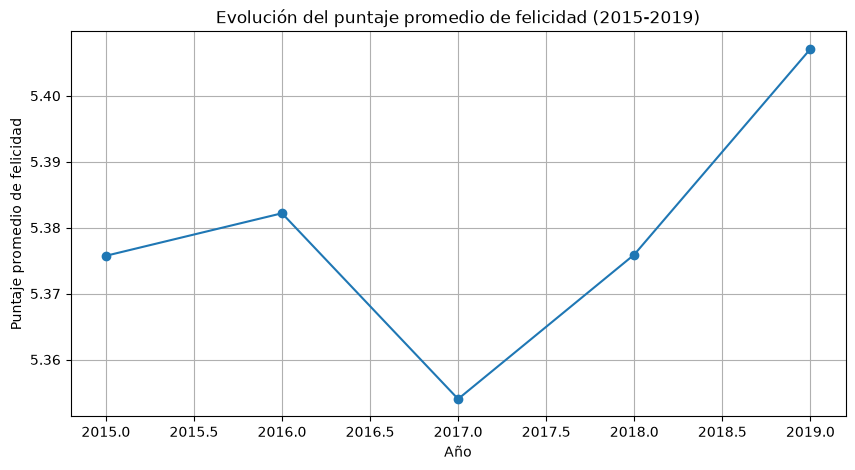

In [16]:
# 14. ANÁLISIS EXPLORATORIO DE DATOS (EDA)

variables_numericas = [
    "happiness_score",
    "gdp_per_capita",
    "social_support",
    "life_expectancy",
    "freedom",
    "corruption",
    "generosity"
]

# Estadísticas descriptivas
print("ESTADÍSTICAS DESCRIPTIVAS")
display(
    df_integrado[variables_numericas]
    .describe()
    .round(3)
)

# Evolución del puntaje de felicidad por año
print("PROMEDIO DE FELICIDAD POR AÑO")

felicidad_anual = (
    df_integrado.groupby("year")["happiness_score"]
    .mean()
)

display(felicidad_anual.round(3))

plt.figure(figsize=(10, 5))
felicidad_anual.plot(marker="o")
plt.title("Evolución del puntaje promedio de felicidad (2015-2019)")
plt.xlabel("Año")
plt.ylabel("Puntaje promedio de felicidad")
plt.grid(True)
plt.show()

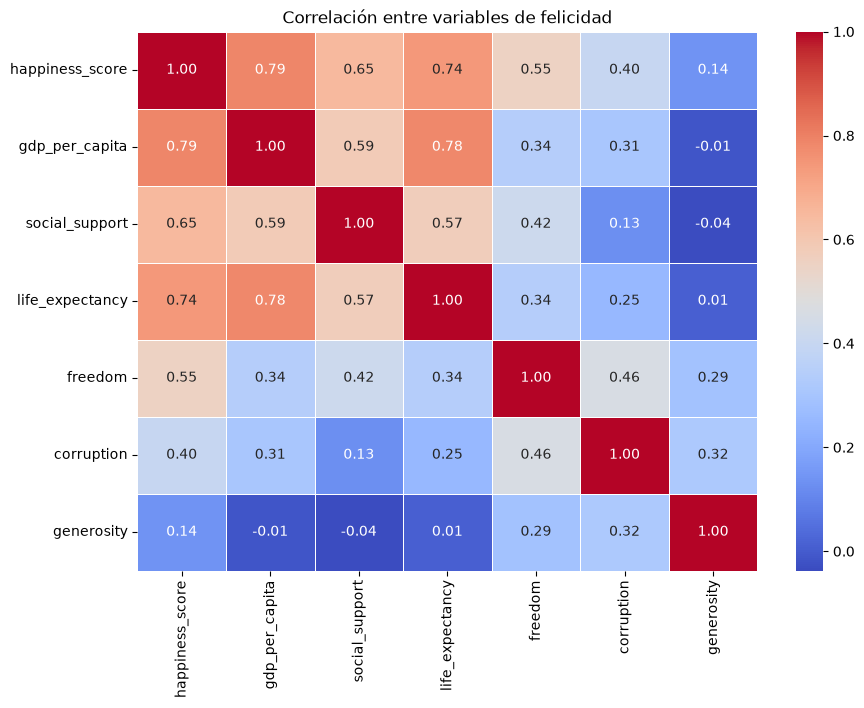

CORRELACIÓN CON EL PUNTAJE DE FELICIDAD:


happiness_score    1.000
gdp_per_capita     0.789
life_expectancy    0.742
social_support     0.649
freedom            0.551
corruption         0.398
generosity         0.138
Name: happiness_score, dtype: float64

In [17]:
# 15. MATRIZ DE CORRELACIÓN

correlaciones = df_integrado[
    variables_numericas
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlación entre variables de felicidad")
plt.show()

print("CORRELACIÓN CON EL PUNTAJE DE FELICIDAD:")

display(
    correlaciones["happiness_score"]
    .sort_values(ascending=False)
    .round(3)
)

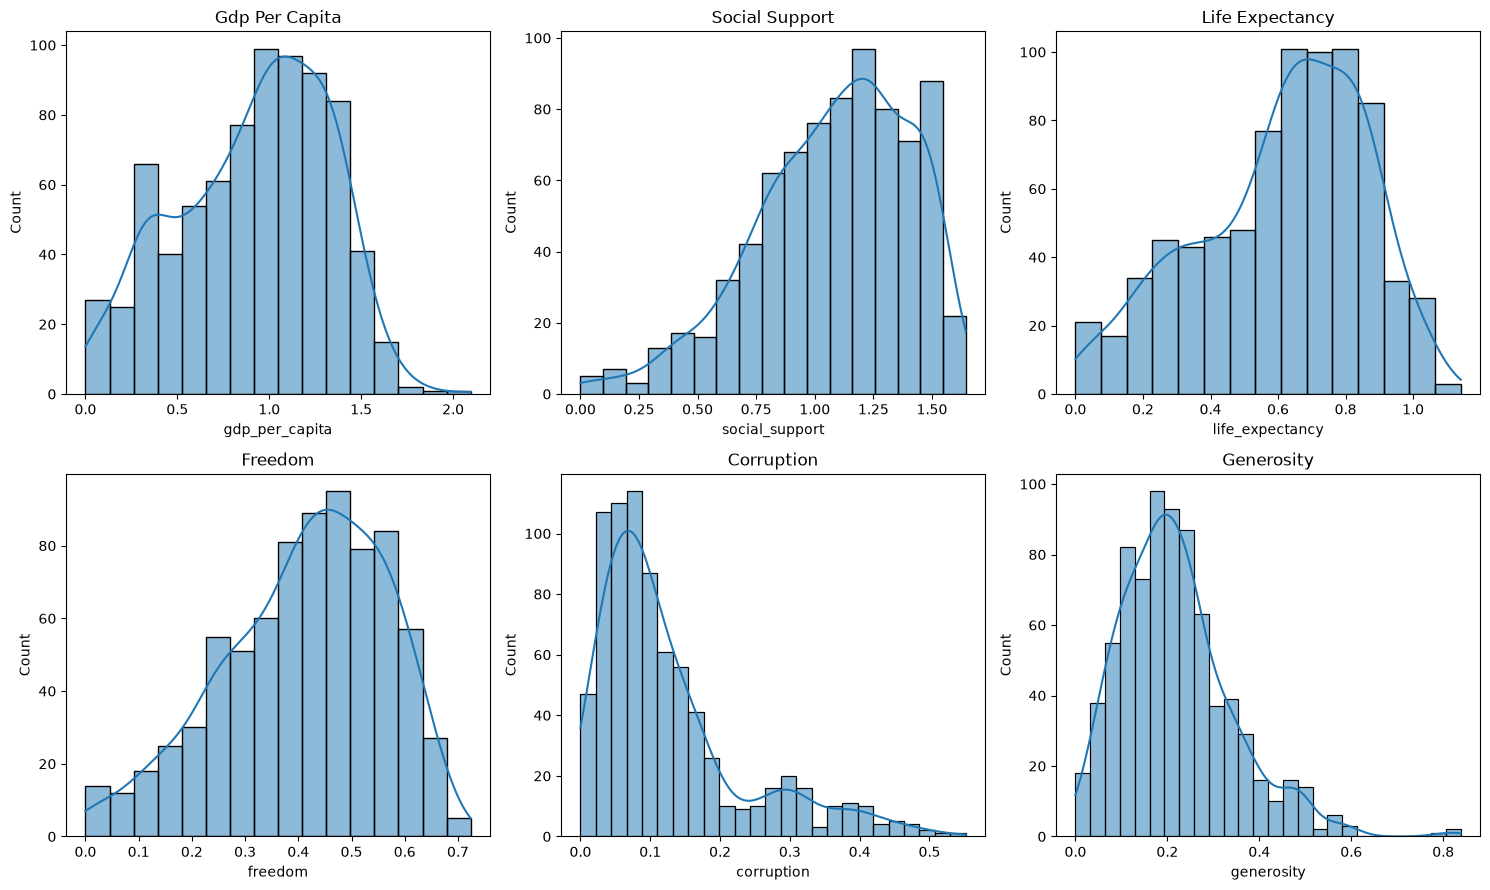

In [18]:
# 16. DISTRIBUCIÓN DE LOS FACTORES PRINCIPALES

factores = [
    "gdp_per_capita",
    "social_support",
    "life_expectancy",
    "freedom",
    "corruption",
    "generosity"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for variable, ax in zip(factores, axes.flatten()):
    sns.histplot(
        data=df_integrado,
        x=variable,
        kde=True,
        ax=ax
    )
    ax.set_title(variable.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [19]:
# 17. PREPARACIÓN DE VARIABLES PARA MACHINE LEARNING

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Variables predictoras
X = df_integrado[
    [
        "gdp_per_capita",
        "social_support",
        "life_expectancy",
        "freedom",
        "corruption",
        "generosity",
        "year"
    ]
]

# Variable objetivo
y = df_integrado["happiness_score"]

# Separación entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("PREPARACIÓN COMPLETADA")
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Variables predictoras:", X.shape[1])
print("Variable objetivo: happiness_score")

PREPARACIÓN COMPLETADA
Registros de entrenamiento: 625
Registros de prueba: 157
Variables predictoras: 7
Variable objetivo: happiness_score


In [20]:
# 18. ENTRENAMIENTO DE LOS MODELOS

# Modelo 1: Regresión lineal
modelo_lineal = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LinearRegression())
])

# Modelo 2: Random Forest
modelo_random = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento
modelo_lineal.fit(X_train, y_train)
modelo_random.fit(X_train, y_train)

print("MODELOS ENTRENADOS CORRECTAMENTE")

MODELOS ENTRENADOS CORRECTAMENTE


In [21]:
# 19. EVALUACIÓN Y COMPARACIÓN

modelos = {
    "Regresión lineal": modelo_lineal,
    "Random Forest": modelo_random
}

resultados = []

for nombre, modelo in modelos.items():

    predicciones = modelo.predict(X_test)

    mae = mean_absolute_error(y_test, predicciones)
    mse = mean_squared_error(y_test, predicciones)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predicciones)

    resultados.append({
        "Modelo": nombre,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

df_resultados = pd.DataFrame(resultados)

display(df_resultados.round(4))

,Modelo,MAE,MSE,RMSE,R2
0,Regresión lineal,0.4699,0.3521,0.5934,0.7193
1,Random Forest,0.3998,0.2811,0.5302,0.7759


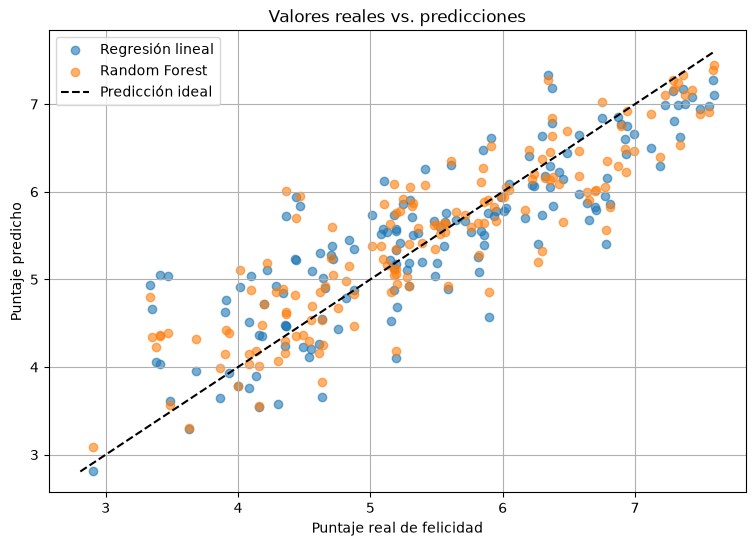

In [22]:
# 20. COMPARACIÓN ENTRE VALORES REALES Y PREDICCIONES

pred_lineal = modelo_lineal.predict(X_test)
pred_random = modelo_random.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    pred_lineal,
    alpha=0.6,
    label="Regresión lineal"
)

plt.scatter(
    y_test,
    pred_random,
    alpha=0.6,
    label="Random Forest"
)

limite_min = min(y_test.min(), pred_lineal.min(), pred_random.min())
limite_max = max(y_test.max(), pred_lineal.max(), pred_random.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "k--",
    label="Predicción ideal"
)

plt.xlabel("Puntaje real de felicidad")
plt.ylabel("Puntaje predicho")
plt.title("Valores reales vs. predicciones")
plt.legend()
plt.grid(True)
plt.show()

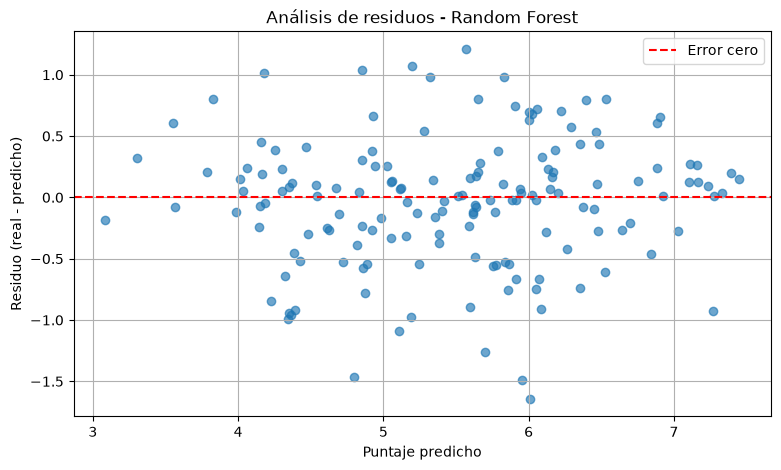

PROMEDIO DE LOS RESIDUOS: -0.0392
DESVIACIÓN ESTÁNDAR: 0.5305
ERROR MÁXIMO ABSOLUTO: 1.6439


In [23]:
# 21. ANÁLISIS DE RESIDUOS - RANDOM FOREST

residuos = y_test - pred_random

plt.figure(figsize=(9, 5))

plt.scatter(
    pred_random,
    residuos,
    alpha=0.65
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Error cero"
)

plt.xlabel("Puntaje predicho")
plt.ylabel("Residuo (real - predicho)")
plt.title("Análisis de residuos - Random Forest")
plt.legend()
plt.grid(True)
plt.show()

print("PROMEDIO DE LOS RESIDUOS:", round(residuos.mean(), 4))
print("DESVIACIÓN ESTÁNDAR:", round(residuos.std(), 4))
print("ERROR MÁXIMO ABSOLUTO:", round(residuos.abs().max(), 4))

In [24]:
# 22. PREPARACIÓN DE RESULTADOS PARA ALMACENAMIENTO

import sqlite3

# Construir tabla de predicciones
df_predicciones = pd.DataFrame({
    "valor_real": y_test.values,
    "prediccion_lineal": pred_lineal,
    "prediccion_random_forest": pred_random,
    "residuo_random_forest": residuos.values
})

print("REGISTROS PARA ALMACENAR:", len(df_predicciones))
display(df_predicciones.head())

REGISTROS PARA ALMACENAR: 157


,valor_real,prediccion_lineal,prediccion_random_forest,residuo_random_forest
0,5.856,5.395341,5.64872,0.20728
1,6.361,6.053865,6.13093,0.23007
2,4.471,5.832101,5.95686,-1.48586
3,6.575,6.648656,6.46760,0.10740
4,7.190,6.293466,6.39204,0.79796


In [25]:
# 23. ALMACENAMIENTO EN BASE DE DATOS SQLITE

conexion = sqlite3.connect("workshop003.db")

# Guardar los datos integrados
df_integrado.to_sql(
    "datos_felicidad",
    conexion,
    if_exists="replace",
    index=False
)

# Guardar las predicciones
df_predicciones.to_sql(
    "predicciones",
    conexion,
    if_exists="replace",
    index=False
)

# Guardar las métricas de evaluación
df_resultados.to_sql(
    "metricas_modelos",
    conexion,
    if_exists="replace",
    index=False
)

conexion.close()

print("BASE DE DATOS CREADA CORRECTAMENTE")
print("Archivo: workshop003.db")

BASE DE DATOS CREADA CORRECTAMENTE
Archivo: workshop003.db


In [26]:
# 24. VERIFICACIÓN DE LOS DATOS ALMACENADOS

conexion = sqlite3.connect("workshop003.db")

tablas = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conexion
)

print("TABLAS ALMACENADAS:")
display(tablas)

print("\nREGISTROS DE FELICIDAD:")
print(pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM datos_felicidad",
    conexion
))

print("\nPREDICCIONES ALMACENADAS:")
print(pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM predicciones",
    conexion
))

conexion.close()

TABLAS ALMACENADAS:


,name
0,datos_felicidad
1,predicciones
2,metricas_modelos



REGISTROS DE FELICIDAD:
   total
0    782

PREDICCIONES ALMACENADAS:
   total
0    157
